In [1]:
#Imports
import astropy
from astropy.io import fits
import glob
import matplotlib.pyplot as plt
import numpy as np
import scipy.stats as stats
from scipy.special import factorial
import os


#Folder extraction 
folder_path = r"C:\Users\Trill\LAB1unzipped"
files_raw = glob.glob(f"{folder_path}/**/*.fit", recursive=True)
print("cell complete")

cell complete


0.05857572236174776


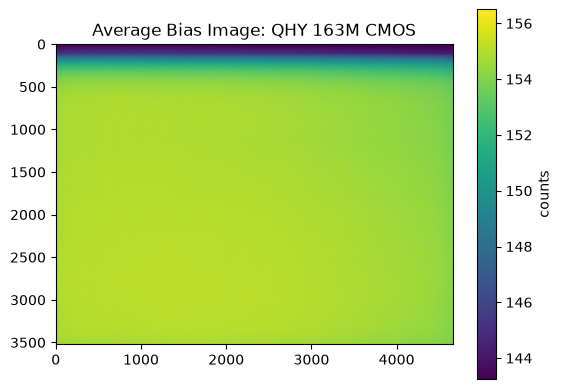

In [24]:
    #File Extraction for Bias Data
bias_phrase = "bias1zachtrillium"
bias_paths = []
for root, _, files in os.walk(folder_path):
    for f in files:
        if bias_phrase in f:
            bias_paths.append(os.path.join(root, f))
bias_paths.sort()

        #Image Correcting
bias_image = {}
bias_corrected_image = {}

for path in bias_paths:
    filename = os.path.basename(path)
    with fits.open(path) as raw_bias:
        bias_image[filename] = {'data': raw_bias[0].data, 'header': raw_bias[0].header}
        bias_corrected_image[filename] = (raw_bias[0].data / 16) + 1

# mean median and std
bias_matrices=list(bias_corrected_image.values())
bias_average=np.mean(bias_matrices,axis=0)


median_bias=np.median(bias_average)


bias_std = np.std(bias_average)
#print(bias_std)

random_error_bias = (bias_matrices[5])-(bias_matrices[11])
average_random_error_bias = np.mean(random_error_bias)
read_noise = (np.std(random_error_bias))/np.sqrt(2)
print(average_random_error_bias)
vmin, vmax = np.percentile(bias_average, [1, 99])
plt.imshow(bias_average, cmap='viridis', vmin=vmin, vmax=vmax)
plt.title("Average Bias Image: QHY 163M CMOS")
plt.colorbar(label='counts')
plt.savefig('Average_Bias_Image.png')

cell complete


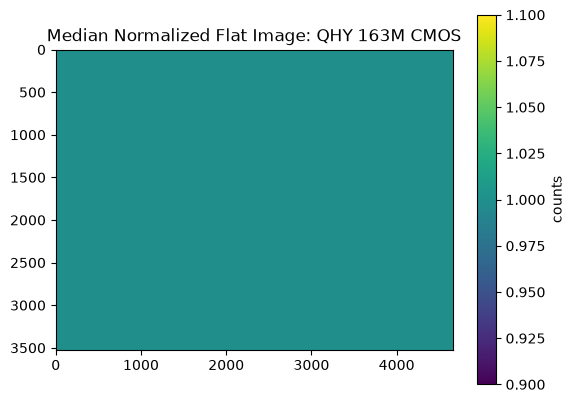

In [9]:

# flat images
flat_phrase = "light1zachtrillium"
flat_paths = []
for root, _, files in os.walk(folder_path):
    for f in files:
        if flat_phrase in f:
            flat_paths.append(os.path.join(root, f))
flat_paths.sort()


flat_image = {}
flat_corrected_image = {}

for path in flat_paths:
    filename = os.path.basename(path)
    with fits.open(path) as raw_flat:
        flat_image[filename] = {'data': raw_flat[0].data, 'header': raw_flat[0].header}
        flat_corrected_image[filename] = (raw_flat[0].data / 16) + 1
corrected_flats = list(flat_corrected_image.values())
flats_3d = np.stack(corrected_flats, axis=0)
flat_median = np.median(flats_3d, axis=0)

normalized_top = (flats_3d)-(bias_average)
normalized_bottom = np.median((flats_3d - bias_average), axis = 0)

normalized_corrected_flat = (normalized_top)/(normalized_bottom)
median_normalized_corrected_flat = np.median(normalized_corrected_flat, axis=0)
vmin, vmax = np.percentile(median_normalized_corrected_flat, [0, 20])
plt.imshow(median_normalized_corrected_flat, cmap='viridis', vmin=vmin, vmax=vmax)
plt.colorbar(label='counts')
plt.title('Median Normalized Flat Image: QHY 163M CMOS')
plt.savefig('Median_Normalized_Flat_image.png')



In [10]:


# vega dark images
dark_vega_phrase = "darkvega1zachtrillium"
dark_vega_paths = []
for root, _, files in os.walk(folder_path):
    for f in files:
        if dark_vega_phrase in f:
            dark_vega_paths.append(os.path.join(root, f))
dark_vega_paths.sort()


dark_vega_image = {}
dark_vega_corrected_image = {}

for path in dark_vega_paths:
    filename = os.path.basename(path)
    with fits.open(path) as raw_dark_vega:
        dark_vega_image[filename] = {'data': raw_dark_vega[0].data, 'header': raw_dark_vega[0].header}
        dark_vega_corrected_image[filename] = (raw_dark_vega[0].data / 16) + 1
dark_vega_matrices=list(dark_vega_corrected_image.values())
dark_vega_matrices_bias = list((dark_vega_matrices-bias_average))
dark_vega_average=np.mean(dark_vega_matrices,axis=0)


median_dark_vega=np.median(dark_vega_average)


dark_vega_std = np.std(dark_vega_average)



# enif dark images
dark_enif_phrase = "dark60s1zachtrillium"
dark_enif_paths = []
for root, _, files in os.walk(folder_path):
    for f in files:
        if dark_enif_phrase in f:
            dark_enif_paths.append(os.path.join(root, f))
dark_enif_paths.sort()


dark_enif_image = {}
dark_enif_corrected_image = {}

for path in dark_enif_paths:
    filename = os.path.basename(path)
    with fits.open(path) as raw_dark_enip:
        dark_enif_image[filename] = {'data': raw_dark_enif[0].data, 'header': raw_dark_enif[0].header}
        dark_enif_corrected_image[filename] = (raw_dark_enif[0].data / 16) + 1
dark_enif_matrices=list(dark_enif_corrected_image.values())
dark_enif_matrices_bias = list((dark_enif_matrices-bias_average))
dark_enif_average=np.mean(dark_enif_matrices_bias,axis=0)


median_dark_enif=np.median(dark_enif_average)


dark_enif_std = np.std(dark_enif_average)



# Alberio B dark images
dark_alberio_phrase = "darkalberio1zachtrillium"
dark_alberio_paths = []
for root, _, files in os.walk(folder_path):
    for f in files:
        if dark_alberio_phrase in f:
            dark_alberio_paths.append(os.path.join(root, f))
dark_alberio_paths.sort()


dark_alberio_image = {}
dark_alberio_corrected_image = {}

for path in dark_alberio_paths:
    filename = os.path.basename(path)
    with fits.open(path) as raw_dark_alberio:
        dark_alberio_image[filename] = {'data': raw_dark_alberio[0].data, 'header': raw_dark_alberio[0].header}
        dark_alberio_corrected_image[filename] = (raw_dark_alberio[0].data / 16) + 1
dark_alberio_matrices=list(dark_alberio_corrected_image.values())
dark_alberio_matrices_bias = list((dark_alberio_matrices-bias_average))
dark_alberio_average=np.mean(dark_alberio_matrices_bias,axis=0)


median_dark_alberio=np.median(dark_alberio_average)


dark_alberio_std = np.std(dark_alberio_average)

print("cell complete")

cell complete


cell complete


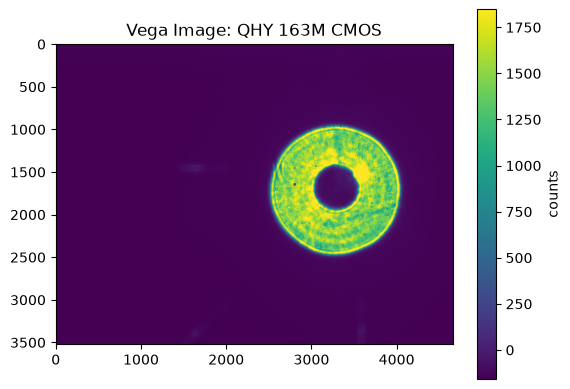

In [11]:


# science images
    #Vega Images
vega_phrase = "lightavegaf1zachtrillium"
vega_paths = []
for root, _, files in os.walk(folder_path):
    for f in files:
        if vega_phrase in f:
            vega_paths.append(os.path.join(root, f))
vega_paths.sort()


vega_image = {}
vega_corrected_image = {}

for path in vega_paths:
    filename = os.path.basename(path)
    with fits.open(path) as raw_vega:
        vega_image[filename] = {'data': raw_vega[0].data, 'header': raw_vega[0].header}
        vega_corrected_image[filename] = (raw_vega[0].data / 16) + 1
vega_matricies = list(vega_corrected_image.values())
science_corrected_vega_top = (vega_matricies)-(dark_vega_average)-(bias_average)
science_corrected_vega = (science_corrected_vega_top)/(median_normalized_corrected_flat)
science_corrected_vega_matricies = list(science_corrected_vega)

image_data_vega = science_corrected_vega_matricies[5]
vmin, vmax = np.percentile(image_data_vega, [1, 99])
plt.imshow(image_data_vega, cmap='viridis', vmin=vmin, vmax=vmax)
plt.colorbar(label='counts')
plt.title('Vega Image: QHY 163M CMOS')
plt.savefig('vega_image.png')
print("cell complete")

cell complete


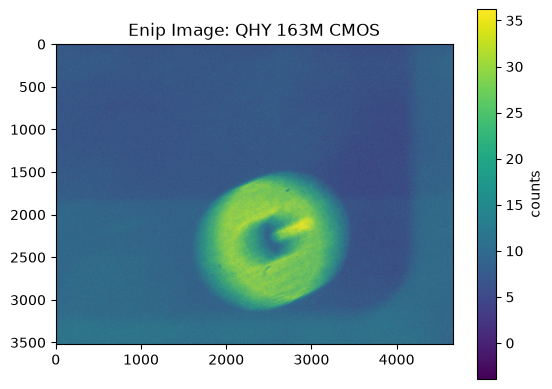

In [12]:
 #Enif Images
enif_phrase = "lighteniff1zachtrillium-"
enif_paths = []
for root, _, files in os.walk(folder_path):
    for f in files:
        if enif_phrase in f:
            enif_paths.append(os.path.join(root, f))
enif_paths.sort()


enif_image = {}
enif_corrected_image = {}

for path in enif_paths:
    filename = os.path.basename(path)
    with fits.open(path) as raw_enif:
        enif_image[filename] = {'data': raw_enif[0].data, 'header': raw_enif[0].header}
        enif_corrected_image[filename] = (raw_enif[0].data / 16) + 1
enif_matricies = list(enif_corrected_image.values())
science_corrected_enif_top = (enif_matricies)-(dark_enif_average)-(bias_average)
science_corrected_enif = (science_corrected_enif_top)/(median_normalized_corrected_flat)
science_corrected_enif_matricies = list(science_corrected_enif)

image_data_enif = science_corrected_enif_matricies[4]
vmin, vmax = np.percentile(image_data_enif, [1, 99])
plt.imshow(image_data_enip, cmap='viridis', vmin=vmin, vmax=vmax)
plt.colorbar(label='counts')
plt.title('Enif Image: QHY 163M CMOS')
plt.savefig('enif_image.png')


cell complete


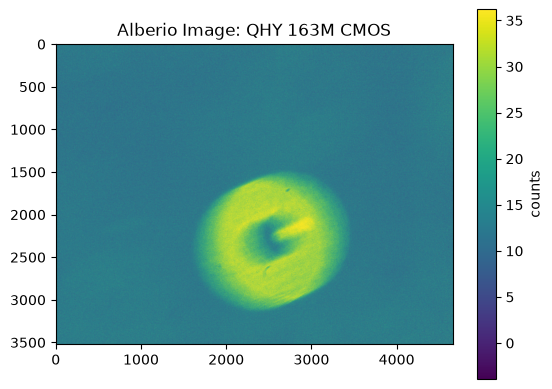

In [22]:
  #Alberio Images
alberio_phrase = "lightalberiobf1zachtrillium-"
alberio_paths = []
for root, _, files in os.walk(folder_path):
    for f in files:
        if alberio_phrase in f:
            alberio_paths.append(os.path.join(root, f))
alberio_paths.sort()


alberio_image = {}
alberio_corrected_image = {}

for path in alberio_paths:
    filename = os.path.basename(path)
    with fits.open(path) as raw_alberio:
        alberio_image[filename] = {'data': raw_alberio[0].data, 'header': raw_alberio[0].header}
        alberio_corrected_image[filename] = (raw_alberio[0].data / 16) + 1
alberio_matricies = list(alberio_corrected_image.values())
science_corrected_alberio_top = (alberio_matricies)-(dark_alberio_average)-(bias_average)
science_corrected_alberio = (science_corrected_alberio_top)/(median_normalized_corrected_flat)
science_corrected_alberio_matricies = list(science_corrected_alberio)

image_data = science_corrected_alberio_matricies[4]
vmin, vmax = np.percentile(image_data_enip, [1, 99])
plt.imshow(image_data, cmap='viridis', vmin=vmin, vmax=vmax)
plt.colorbar(label='counts')
plt.title('Alberio  B Image: QHY 163M CMOS')
plt.savefig('Alberio_image.png')



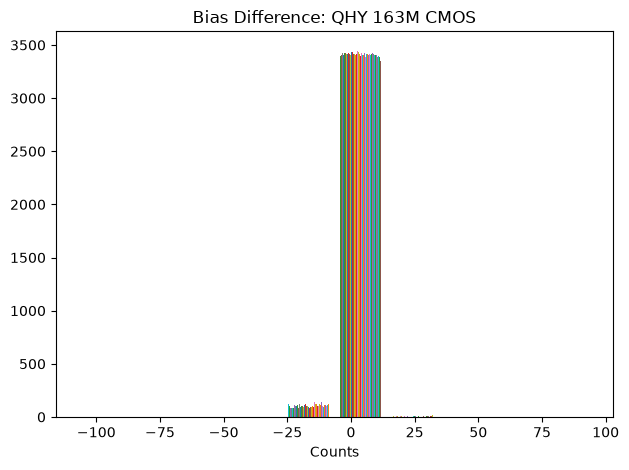

cell complete


In [21]:
plt.hist(random_error_bias, bins=10)
plt.title("Bias Difference: QHY 163M CMOS")
plt.xlabel('Counts')
plt.tight_layout()
plt.savefig('Bias_Difference.png')
plt.show()
print("cell complete")

In [25]:
print(median_bias)
print(read_noise)

154.7
2.5441605642976763
